# 5. O texto dos chamados: unir 14 anos de descrições de serviço

Os dados do 156 não têm campo de texto livre: o cidadão não descreve o problema com as próprias palavras. O único texto é a descrição do serviço pedido ("REMOCAO DE ENTULHOS", "PODA DE ARVORES"), escolhida de uma lista. Mesmo assim há um problema de texto real e com valor de negócio: essa lista mudou. Até 2023 os códigos eram outros e os acentos foram cortados na origem ("ILUMINAO PBLICA"), por isso o projeto analisa só 2024 e 2025 (notebook 01). Se for possível traduzir as descrições antigas para a taxonomia atual, a prefeitura ganha 14 anos de histórico comparável em vez de 2.

A pergunta: um modelo treinado só com as descrições atuais consegue dizer a que grupo pertence uma descrição antiga que ele nunca viu? E qual é o serviço atual equivalente?

O código fica em [`src/nlp/service_text.py`](../src/nlp/service_text.py); `make nlp` baixa os arquivos de 2012 a 2023, roda tudo e atualiza [`docs/nlp_results.md`](../docs/nlp_results.md) e o de-para sugerido em [`docs/service_mapping.csv`](../docs/service_mapping.csv).

In [1]:
import pandas as pd

from src.analysis.charts import plot_confusion
from src.config import DOCS_DIR
from src.nlp.service_text import (
    CURRENT_YEARS,
    HISTORIC_YEARS,
    build_datasets,
    evaluate,
    service_catalog,
)

catalog = service_catalog(CURRENT_YEARS + HISTORIC_YEARS)
catalog.groupby("year").agg(services=("service", "nunique"), tickets=("tickets", "sum"))

,services,tickets
year,,
2012,100,98268
2013,93,100317
2014,88,89810
2015,91,82325
2016,87,79877
2017,87,87104
2018,87,86460
2019,83,95616
2020,86,88488


De 2012 a 2025 a lista oscila entre 82 e 100 descrições por ano (contando as usadas em pelo menos 5 chamados), com 80 a 115 mil chamados por ano. São poucas centenas de textos curtos: pouco volume, mas é isso que decide se 12 anos de dados podem ser comparados com os atuais.

## Os rótulos: traduzindo os grupos antigos

Para avaliar, cada descrição antiga precisa do seu grupo na taxonomia atual. Os nomes de grupo antigos são os mesmos de hoje com as letras acentuadas apagadas, então a tradução procura o grupo atual que contém o nome antigo letra por letra (`match_group`). Grupos que não existem mais, como necrópoles, ficam de fora.

In [2]:
train, test = build_datasets(catalog)
print(f"Treino: {len(train)} descrições atuais. Teste: {len(test)} descrições antigas inéditas.")
test.sort_values("tickets", ascending=False).head(8)[
    ["service", "group", "tickets", "first_year", "last_year"]
]

Treino: 94 descrições atuais. Teste: 77 descrições antigas inéditas.


,service,group,tickets,first_year,last_year
34,MANUTENO EM LMPADA APAGADA,ILUMINACAO PUBLICA,150114,2013,2023
29,"LIMP. DE GALERIAS,VALETAS,SARJETAS",DRENAGEM,52733,2012,2023
67,REMOO DE ENTULHOS,LIMPEZA URBANA,30674,2013,2023
38,OPERACAO TAPA-BURACO EM ASFALTO,PAVIMENTACAO,22396,2012,2022
39,OPERAO TAPA-BURACO EM ASFALTO,PAVIMENTACAO,17348,2013,2023
4,CAPINAO EM VIA PAVIMENTADA,LIMPEZA URBANA,13756,2013,2023
72,"REPOSIO TAMPA DE POO, GALERIAS E PRE-MOLDADOS",DRENAGEM,12631,2013,2023
70,"REPOSICAO TAMPA DE POCO, GALERIAS E PRE-MOLDADOS",DRENAGEM,11965,2012,2022


O treino tem 94 descrições atuais. O teste tem 77 descrições antigas que não aparecem em 2024 e 2025, e elas não são raras: as maiores somam dezenas de milhares de chamados cada, a começar por "MANUTENO EM LMPADA APAGADA", com 150 mil.

## Reparando as palavras quebradas

O mesmo corte de letras acentuadas quebra as palavras dentro das descrições: "MANUTENO EM LMPADA APAGADA" é a descrição antiga mais usada, com 150 mil chamados. Para um modelo de linguagem, "MANUTENO" e "LMPADA" não são palavras. O reparo (`repair_text`) troca cada palavra desconhecida pela palavra mais comum do vocabulário atual que a contém letra por letra e começa com a mesma letra.

In [3]:
repaired = test[test["service"] != test["service_repaired"]]
print(f"{len(repaired)} de {len(test)} descrições tiveram alguma palavra reparada")
repaired.sort_values("tickets", ascending=False).head(6)[["service", "service_repaired", "tickets"]]

29 de 77 descrições tiveram alguma palavra reparada


,service,service_repaired,tickets
34,MANUTENO EM LMPADA APAGADA,MANUTENCAO EM LAMPADA APAGADA,150114
67,REMOO DE ENTULHOS,REMOCAO DE ENTULHOS,30674
38,OPERACAO TAPA-BURACO EM ASFALTO,OPERACAO TAPA-BURACO EM ASFALTICO,22396
39,OPERAO TAPA-BURACO EM ASFALTO,OPERACAO TAPA-BURACO EM ASFALTICO,17348
4,CAPINAO EM VIA PAVIMENTADA,CAPINACAO EM VIA PAVIMENTADA,13756
72,"REPOSIO TAMPA DE POO, GALERIAS E PRE-MOLDADOS","REPOSICAO TAMPA DE POCO, GALERIAS E PRE-MOLDADOS",12631


O reparo acerta as grandes ("MANUTENCAO EM LAMPADA APAGADA", "REMOCAO DE ENTULHOS", "CAPINACAO EM VIA PAVIMENTADA") e erra pouco: "ASFALTO" vira "ASFALTICO", uma palavra parecida que existe no vocabulário atual.

## Três formas de classificar

- n-gramas de caracteres (TF-IDF) com regressão logística, o baseline clássico para textos curtos com grafias quebradas;
- embeddings de um transformer multilíngue pré-treinado (`paraphrase-multilingual-MiniLM-L12-v2`) com regressão logística;
- os mesmos embeddings, atribuindo à descrição antiga o grupo do serviço atual mais parecido (similaridade de cosseno), que é também o de-para sugerido.

In [4]:
runs = {
    "original": evaluate(train, test, "service"),
    "com reparo": evaluate(train, test, "service_repaired"),
}
pd.concat({label: pd.DataFrame(run["results"]).T for label, run in runs.items()}).round(3)

accuracy  \
original   Caracteres (TF-IDF) + regressão logística          0.779   
           Embeddings (transformer) + regressão logística     0.597   
           Embeddings: serviço atual mais parecido            0.675   
com reparo Caracteres (TF-IDF) + regressão logística          0.766   
           Embeddings (transformer) + regressão logística     0.597   
           Embeddings: serviço atual mais parecido            0.688   

                                                           ticket_accuracy  \
original   Caracteres (TF-IDF) + regressão logística                 0.974   
           Embeddings (transformer) + regressão logística            0.907   
           Embeddings: serviço atual mais parecido                   0.598   
com reparo Caracteres (TF-IDF) + regressão logística                 0.973   
           Embeddings (transformer) + regressão logística            0.907   
           Embeddings: serviço atual mais parecido                   0.941   

                                                           f1_macro  \
original   Caracteres (TF-IDF) + regressão logística          0.620   
           Embeddings (transformer) + regressão logística     0.447   
           Embeddings: serviço atual mais parecido            0.499   
com reparo Caracteres (TF-IDF) + regressão logística          0.614   
           Embeddings (transformer) + regressão logística     0.447   
           Embeddings: serviço atual mais parecido            0.507   

                                                           f1_weighted  
original   Caracteres (TF-IDF) + regressão logística             0.771  
           Embeddings (transformer) + regressão logística        0.629  
           Embeddings: serviço atual mais parecido               0.680  
com reparo Caracteres (TF-IDF) + regressão logística             0.754  
           Embeddings (transformer) + regressão logística        0.629  
           Embeddings: serviço atual mais parecido               0.697

Para dizer o grupo, o baseline de n-gramas de caracteres ganha do transformer: acerta 78% das descrições antigas, que somam 97% dos chamados, contra 60% do classificador sobre embeddings. Textos curtos, com abreviações ("LIMP.", "RECUP.") e grafias quebradas, favorecem pedaços de palavras; o transformer foi pré-treinado em frases naturais e perde informação quando a palavra não existe. O reparo pouco muda os classificadores, mas é decisivo para a busca do serviço mais parecido: com ele, a descrição de 150 mil chamados encontra o serviço certo, e a parcela de chamados no grupo certo sobe de 60% para 94%.

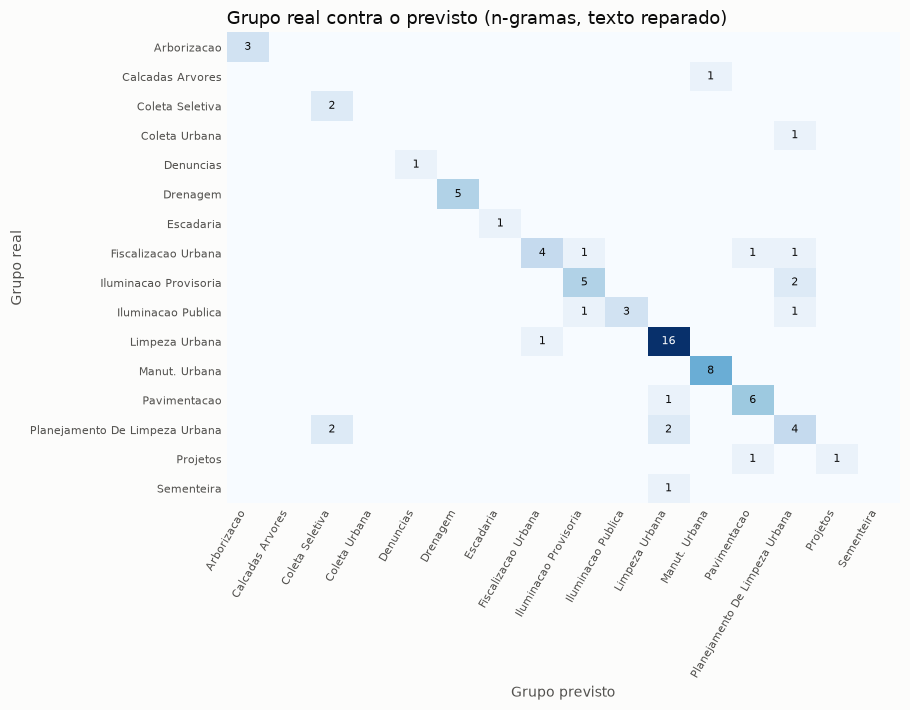

In [5]:
run = runs["com reparo"]
plot_confusion(
    run["confusion"],
    DOCS_DIR / "img" / "nlp_confusion.png",
    "Grupo real contra o previsto (n-gramas, texto reparado)",
)

Os erros ficam entre grupos vizinhos: planejamento de limpeza urbana confundido com limpeza urbana e coleta seletiva, iluminação provisória com iluminação pública, fiscalização urbana espalhada entre vários grupos. São fronteiras que também confundiriam uma pessoa lendo só a descrição.

## O de-para sugerido

In [6]:
mapping = run["mapping"].assign(right_group=lambda df: df["group"] == df["suggested_group"])
mapping.head(10)[["service", "suggested_service", "similarity", "right_group", "tickets"]]

,service,suggested_service,similarity,right_group,tickets
34,MANUTENO EM LMPADA APAGADA,MANUTENCAO EM LAMPADA APAGADA,1.000,True,150114
29,"LIMP. DE GALERIAS,VALETAS,SARJETAS","REPOSICAO TAMPA DE POCO, GALERIAS,MEIO FIO E P...",0.855,True,52733
67,REMOO DE ENTULHOS,REMOCAO DE ENTULHOS,1.000,True,30674
38,OPERACAO TAPA-BURACO EM ASFALTO,RECAPEAMENTO ASFALTICO,0.896,True,22396
39,OPERAO TAPA-BURACO EM ASFALTO,RECAPEAMENTO ASFALTICO,0.896,True,17348
4,CAPINAO EM VIA PAVIMENTADA,CAPINACAO EM VIA PAVIMENTADA,1.000,True,13756
72,"REPOSIO TAMPA DE POO, GALERIAS E PRE-MOLDADOS","REPOSICAO TAMPA DE POCO, GALERIAS,MEIO FIO E P...",0.986,True,12631
70,"REPOSICAO TAMPA DE POCO, GALERIAS E PRE-MOLDADOS","REPOSICAO TAMPA DE POCO, GALERIAS,MEIO FIO E P...",0.986,True,11965
3,CAPINAO EM VIA NO PAVIMENTADA,CAPINACAO EM VIA NAO PAVIMENTADA,1.000,True,11214
53,RECUPERAO DE PAVIMENTO PARALELEPIPEDO,RECUPERACAO DE PAVIMENTO PARALELEPIPEDO,1.000,True,10261


In [7]:
bands = pd.cut(mapping["similarity"], [0, 0.8, 0.9, 1.0])
mapping.groupby(bands, observed=True).agg(
    descriptions=("service", "size"),
    right_group=("right_group", "mean"),
    tickets=("tickets", "sum"),
).round(2)

,descriptions,right_group,tickets
similarity,,,
"(0.0, 0.8]",33,0.58,35980
"(0.8, 0.9]",21,0.52,130288
"(0.9, 1.0]",23,1.00,272146


A similaridade funciona como grau de confiança. Acima de 0,9, todas as 23 descrições caem no grupo certo e o serviço sugerido é o equivalente atual; elas somam 272 mil chamados. Abaixo disso o acerto cai para pouco mais da metade e a sugestão vira ponto de partida para revisão: "LIMP. DE GALERIAS,VALETAS,SARJETAS" (53 mil chamados), por exemplo, está no grupo certo, mas corresponde a limpeza de galerias e valetas, não à reposição de tampas sugerida.

## Conclusão

Para classificar o grupo de uma descrição antiga, o baseline de n-gramas de caracteres é o método recomendado: mais simples, mais rápido e melhor que o transformer neste texto. Os embeddings, com o reparo das palavras, servem para outra tarefa: sugerir o serviço atual equivalente. Daqui sai um de-para semiautomático:

- aceitar direto as sugestões com similaridade acima de 0,9 (23 descrições, 272 mil chamados);
- revisar à mão as outras 54, já com o grupo previsto e o serviço mais parecido como ponto de partida;
- as descrições antigas idênticas às atuais não precisam de nada.

Com o de-para revisado, a análise pode passar de 2 para 14 anos, o que daria tendências de longo prazo e muito mais dias de chuva para testar a hipótese H3.

Limitações:

- o texto é uma lista fechada de descrições, não o relato do cidadão, então não há NLP possível sobre o problema em si;
- treino e teste são pequenos (94 e 77 descrições), e cada erro mexe vários pontos no F1 macro;
- os rótulos do teste vêm da tradução automática dos grupos antigos, e grupos extintos ficam de fora;
- o reparo pode trocar uma palavra por outra parecida ("ASFALTO" por "ASFALTICO").